<a href="https://colab.research.google.com/github/xsai-max/Belajar-OpenSeesPy-Sipil/blob/main/Latihan1_Kantilever.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lendutan di ujung balok (Node 2) = -0.00667 meter


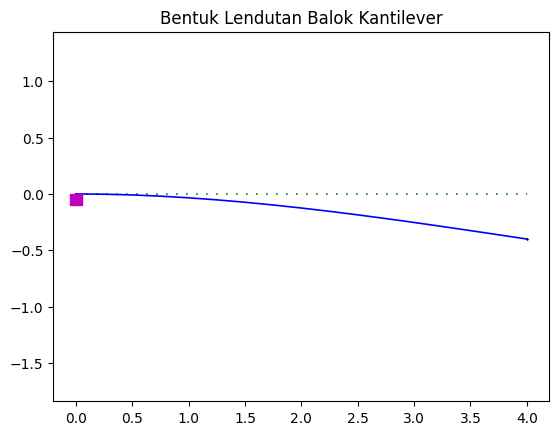

In [1]:
# 1. Instal OpenSeesPy dan alat gambarnya di Google Colab
!pip install -q openseespy opsvis

import openseespy.opensees as ops
import opsvis as opsv
import matplotlib.pyplot as plt

# 2. Mulai model baru (2D, 3 DOF per titik)
ops.wipe()
ops.model('basic', '-ndm', 2, '-ndf', 3)

# 3. Buat 2 titik (Node 1 di x=0, Node 2 di x=4 meter)
ops.node(1, 0.0, 0.0)
ops.node(2, 4.0, 0.0)

# 4. Pasang tumpuan jepit di Node 1 (kunci X, Y, dan Momen)
ops.fix(1, 1, 1, 1)

# 5. Sambungkan Node 1 dan 2 dengan balok beton (A, E, I)
ops.geomTransf('Linear', 1)
ops.element('elasticBeamColumn', 1, 1, 2, 0.12, 2e7, 0.0016, 1)

# 6. Beri beban terpusat 10 kN ke bawah (-10) di ujung bebas (Node 2)
ops.timeSeries('Linear', 1)
ops.pattern('Plain', 1, 1)
ops.load(2, 0.0, -10.0, 0.0)

# 7. Jalankan perhitungan!
ops.system('BandGeneral')
ops.numberer('RCM')
ops.constraints('Plain')
ops.integrator('LoadControl', 1.0)
ops.algorithm('Linear')
ops.analysis('Static')
ops.analyze(1)

# 8. Tampilkan hasil lendutan dan gambar bentuk strukturnya
lendutan_ujung = ops.nodeDisp(2, 2)
print(f"Lendutan di ujung balok (Node 2) = {lendutan_ujung:.5f} meter")

opsv.plot_defo()
plt.title("Bentuk Lendutan Balok Kantilever")
plt.show()
